# Complexity analysis: visualization module

Here I analyze the functions of `src/visualization`, line by line and globally. Then I optimize the function that plots all the curves and I compare the times.

Sizes used:

* C: number of curves (940) and m: points of one curve (about 10)
* N: curves of the table of features, K: number of groups (3)
* d_f: features in one figure and g: points where a density is evaluated
* U: points of a ROC curve and s: sets of features
* d_m: points of the covariance matrix (8)

The cost of a plot has two parts: the work done in Python to build the objects (this is what I count) and the drawing of the image, that is proportional to the number of segments. In the times I use `fig.canvas.draw()` so that the drawing is included.

In [1]:
import os
import sys
import timeit

sys.path.append(os.path.abspath(os.path.join("..", "..")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import GROUPS, COLORS
from src.preprocessing.optimized import build_curve_data_groupby
from src.visualization import plots
from src.visualization.optimized import plot_all_curves_fast


def measure(func, *args, repeats=3):
    return timeit.timeit(lambda: func(*args), number=repeats) / repeats


processed = os.path.join("..", "..", "data", "processed")
usable = pd.read_csv(os.path.join(processed, "usable_curves.csv"), index_col="layer_id")
points_table = pd.read_csv(os.path.join(processed, "selected_points.csv"))
curve_data = build_curve_data_groupby(points_table)
print("curves:", len(curve_data))

curves: 940


## 1. Analysis of the functions

### plot_group_counts_and_curves

```python
def plot_group_counts_and_curves(usable, curve_data, groups):
    """Bar plot with the curves of each group and plot of all the curves."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    counts = usable["texture_group"].value_counts()[groups]
    axes[0].bar(counts.index, counts.values, color=[COLORS[g] for g in counts.index])
    axes[0].set_ylabel("Number of curves")
    axes[0].set_title("Curves per texture group")

    for layer_id, (psi, theta) in curve_data.items():
        group = usable.loc[layer_id, "texture_group"]
        axes[1].plot(psi, theta, color=COLORS[group], alpha=0.12)
    for group in groups:
        axes[1].plot([], [], color=COLORS[group], label=group)
    axes[1].set_xscale("symlog", linthresh=0.1)
    axes[1].set_xlabel("Matric potential psi (m)")
    axes[1].set_ylabel("Water content theta (m3/m3)")
    axes[1].set_title("All the curves")
    axes[1].legend()
    plt.tight_layout()
    return fig
```

* `plt.subplots(1, 2, ...)`: O(1)
* `usable["texture_group"].value_counts()[groups]`: O(C)
* `axes[0].bar(...)` and the labels: O(K)
* `for layer_id, (psi, theta) in curve_data.items()`: C iterations
* `usable.loc[layer_id, "texture_group"]`: O(1)
* `axes[1].plot(psi, theta, ...)`: O(m) and a fixed cost to create one line object
* the loop of the legend: O(K)
* the scale, the labels, the legend and `plt.tight_layout()`: O(1) with respect to C

**Total:** O(C m) in time and in space (one line object with its arrays for each curve). The drawing is also proportional to C m.

### plot_feature_densities

```python
def plot_feature_densities(dataset, domain_name, columns, groups):
    """Density plot of each feature of a domain, one line per group."""
    n_rows = (len(columns) + 2) // 3
    fig = plt.figure(figsize=(14, 3.6 * n_rows))
    for i, feature in enumerate(columns):
        plt.subplot(n_rows, 3, i + 1)
        sns.kdeplot(data=dataset, x=feature, hue="texture_group", hue_order=groups, palette=COLORS,
                    common_norm=False, fill=True, alpha=0.3)
        plt.title(feature)
    fig.suptitle("Density by texture group: " + domain_name)
    plt.tight_layout()
    return fig
```

* `plt.figure(...)`: O(1)
* the loop has d_f iterations
* `plt.subplot(...)`: O(1)
* `sns.kdeplot(..., hue=...)`: a Gaussian KDE evaluated at g points for each of the K groups: O(N g) for all the groups
* `plt.title(...)`, `suptitle` and `tight_layout`: O(d_f)

**Total:** O(d_f N g). The KDE is the expensive part.

### plot_confusion_and_roc

```python
def plot_confusion_and_roc(matrix, roc_curves, groups):
    """Confusion matrix and one-vs-rest ROC curves. roc_curves is a dictionary group -> (fpr, tpr, auc)."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    axes[0].imshow(matrix, cmap="Blues")
    axes[0].set_xticks(range(len(groups)))
    axes[0].set_xticklabels(groups)
    axes[0].set_yticks(range(len(groups)))
    axes[0].set_yticklabels(groups)
    axes[0].set_xlabel("Predicted group")
    axes[0].set_ylabel("True group")
    axes[0].set_title("Confusion matrix")
    for i in range(len(groups)):
        for j in range(len(groups)):
            axes[0].text(j, i, str(matrix[i, j]), ha="center", va="center")

    for group in groups:
        fpr, tpr, auc = roc_curves[group]
        axes[1].plot(fpr, tpr, color=COLORS[group], label=group + " (AUC " + str(round(auc, 3)) + ")")
    axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
    axes[1].set_xlabel("False positive rate (1 - specificity)")
    axes[1].set_ylabel("True positive rate (sensitivity)")
    axes[1].set_title("ROC curves")
    axes[1].legend()
    plt.tight_layout()
    return fig
```

* `imshow(matrix)`: O(K^2)
* the ticks and the labels: O(K)
* the double loop with `text`: K^2 iterations of O(1)
* the loop over K groups with `plot(fpr, tpr)`: O(U) each one
* the diagonal, the labels and the legend: O(K)

**Total:** O(K^2 + K U).

### plot_feature_set_comparison

```python
def plot_feature_set_comparison(summary, baseline):
    """Bar plot of accuracy and macro F1 for each set of features. summary has the mean and std of each one."""
    means = summary.xs("mean", axis=1, level=1)[["accuracy", "macro F1"]]
    stds = summary.xs("std", axis=1, level=1)[["accuracy", "macro F1"]]
    positions = np.arange(len(means))
    width = 0.35

    fig = plt.figure(figsize=(9, 4.5))
    plt.bar(positions - width / 2, means["accuracy"], width, yerr=stds["accuracy"], label="accuracy")
    plt.bar(positions + width / 2, means["macro F1"], width, yerr=stds["macro F1"], label="macro F1")
    plt.axhline(baseline, color="black", linestyle="--", label="baseline")
    plt.xticks(positions, means.index, rotation=15)
    plt.ylim(0, 1)
    plt.ylabel("Test score")
    plt.title("Texture recognition by set of features")
    plt.legend()
    plt.tight_layout()
    return fig
```

* `summary.xs(...)` two times: O(s)
* `np.arange(len(means))`: O(s)
* `plt.bar(...)` two times: O(s)
* `axhline`, ticks, labels and legend: O(s)

**Total:** O(s).

### plot_fit_and_derivative

```python
def plot_fit_and_derivative(curve, model, derivative):
    """Measured curve with the van Genuchten fit, and the slope of the curve."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    psi = np.logspace(-1, 3, 200)
    axes[0].plot(curve.psi, curve.theta, "ko", label="measured")
    axes[0].plot(psi, model(psi), "r", label="van Genuchten fit")
    axes[0].set_xscale("log")
    axes[0].set_xlabel("Matric potential psi (m)")
    axes[0].set_ylabel("theta (m3/m3)")
    axes[0].set_title("Curve " + str(curve.layer_id))
    axes[0].legend()

    log_psi = np.linspace(0.05, 1.95, 191)
    axes[1].plot(log_psi, derivative(log_psi))
    axes[1].set_xlabel("log10(psi)")
    axes[1].set_ylabel("d theta / d log10(psi)")
    axes[1].set_title("Slope of the curve")
    plt.tight_layout()
    return fig
```

* `np.logspace(-1, 3, 200)`: O(200)
* `plot(curve.psi, curve.theta)`: O(m)
* `model(psi)`: O(200) and its `plot`: O(200)
* `np.linspace(0.05, 1.95, 191)`: O(g)
* `derivative(log_psi)`: O(g log m)
* the last `plot`: O(g)

**Total:** O(g log m), a fixed cost for each figure.

### plot_covariance

```python
def plot_covariance(cov, psi_grid):
    """Covariance between the potentials of psi_grid."""
    fig = plt.figure(figsize=(5.5, 4.5))
    plt.imshow(cov, cmap="viridis")
    plt.colorbar()
    plt.xticks(range(len(psi_grid)), psi_grid)
    plt.yticks(range(len(psi_grid)), psi_grid)
    plt.xlabel("psi (m)")
    plt.ylabel("psi (m)")
    plt.title("Covariance of theta between potentials")
    plt.tight_layout()
    return fig
```

* `plt.imshow(cov)`: O(d_m^2)
* `plt.colorbar()`, the ticks and the labels: O(d_m)

**Total:** O(d_m^2).

## 2. Optimization: one plot call per group

Only the function that plots all the curves depends on the number of curves, and it creates C line objects. In the optimized version the curves of each group are joined in one array with `nan` between them, so there are only K plot calls (the lines are not joined where there is a `nan`).

### plot_all_curves_fast (optimized)

```python
def plot_all_curves_fast(usable, curve_data, groups):
    """Plot all the curves with only one plot call per group. The curves are joined with nan between them."""
    fig = plt.figure(figsize=(6, 4.5))
    for group in groups:
        psi_list = []
        theta_list = []
        for layer_id, (psi, theta) in curve_data.items():
            if usable.loc[layer_id, "texture_group"] == group:
                psi_list.append(np.append(psi, np.nan))
                theta_list.append(np.append(theta, np.nan))
        plt.plot(np.concatenate(psi_list), np.concatenate(theta_list), color=COLORS[group], alpha=0.12, label=group)
    plt.xscale("symlog", linthresh=0.1)
    plt.xlabel("Matric potential psi (m)")
    plt.ylabel("Water content theta (m3/m3)")
    plt.legend()
    return fig
```

* `plt.figure(...)`: O(1)
* the loop over K groups
* inside it, the loop over the C curves with `usable.loc[...] == group`: O(1) each one, so O(K C) in total
* `np.append(psi, np.nan)` and `np.append(theta, np.nan)`: O(m) each one, and every curve enters in one group only: O(C m) in total
* `np.concatenate(...)`: O(R_g), the points of the group; O(C m) for the three groups
* `plt.plot(...)` with one line per group: O(C m) in total

**Total:** O(K C + C m) = O(C m) because K = 3. The order is the same as in the first version, but only 3 line objects are created and not 940.

### Same figure and times

In [2]:
def draw_first(sub_usable, sub_data):
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for layer_id, (psi, theta) in sub_data.items():
        group = sub_usable.loc[layer_id, "texture_group"]
        ax.plot(psi, theta, color=COLORS[group], alpha=0.12)
    ax.set_xscale("symlog", linthresh=0.1)
    fig.canvas.draw()
    plt.close(fig)


def draw_fast(sub_usable, sub_data):
    fig = plot_all_curves_fast(sub_usable, sub_data, GROUPS)
    fig.canvas.draw()
    plt.close(fig)


fig = plot_all_curves_fast(usable, curve_data, GROUPS)
n_points_drawn = sum(len(line.get_xdata()) for line in fig.axes[0].lines)
n_points_data = sum(len(v[0]) + 1 for v in curve_data.values())
print("points in the lines of the optimized figure:", n_points_drawn, "| points of the data (with one nan per curve):", n_points_data)
plt.close(fig)

points in the lines of the optimized figure: 9993 | points of the data (with one nan per curve): 9993


In [3]:
ids = list(curve_data.keys())
sizes = [100, 200, 400, 800, len(ids)]
t_first = []
t_fast = []
for k in sizes:
    sub_data = {i: curve_data[i] for i in ids[:k]}
    t_first.append(measure(draw_first, usable, sub_data))
    t_fast.append(measure(draw_fast, usable, sub_data))

timing = pd.DataFrame({"C": sizes, "one plot per curve (s)": t_first, "one plot per group (s)": t_fast})
timing["speed-up"] = timing["one plot per curve (s)"] / timing["one plot per group (s)"]
timing.round(4)

,C,one plot per curve (s),one plot per group (s),speed-up
0,100,0.1300,0.0816,1.5942
1,200,0.1597,0.1228,1.3005
2,400,0.2515,0.1326,1.8964
3,800,0.4440,0.2105,2.1097
4,940,0.5120,0.2123,2.4121


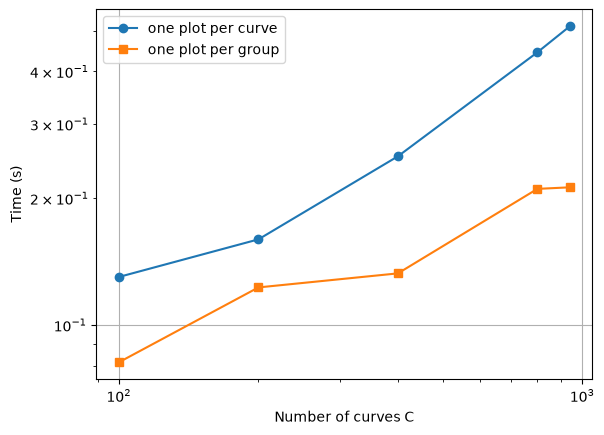

speed-up with 940 curves: 2.4 times


In [4]:
plt.loglog(sizes, t_first, "o-", label="one plot per curve")
plt.loglog(sizes, t_fast, "s-", label="one plot per group")
plt.xlabel("Number of curves C")
plt.ylabel("Time (s)")
plt.legend()
plt.grid(True)
plt.show()
print("speed-up with", sizes[-1], "curves:", round(timing["speed-up"].iloc[-1], 1), "times")

Both versions grow with C, as the analysis says (O(C m)). The optimized version has a smaller constant because it creates only one object for each group.

## 3. Summary

| Function | Time |
|---|---|
| `plot_group_counts_and_curves` | O(C m) |
| `plot_all_curves_fast` (optimized) | O(C m), with only K line objects |
| `plot_feature_densities` | O(d_f N g) |
| `plot_confusion_and_roc` | O(K^2 + K U) |
| `plot_feature_set_comparison` | O(s) |
| `plot_fit_and_derivative` | O(g log m) |
| `plot_covariance` | O(d_m^2) |

The plots are not the main cost of the project: the profile of the analysis module shows that the fit of the van Genuchten model takes almost all the time of the features.